<a href="https://colab.research.google.com/github/ilyak0n/image_processing/blob/main/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%961_%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%BE%D0%B1%D1%8A%D0%B5%D0%BA%D1%82%D0%BE%D0%B2_%D0%BD%D0%B0_%D0%B8%D0%B7%D0%BE%D0%B1%D1%80%D0%B0%D0%B6%D0%B5%D0%BD%D0%B8%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Проектная работа №1: Классификация объектов на изображении**









In [609]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

### **Цель:**


Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.


### **Базовая реализация:**



1. **Сбор изображения:**
   - Используйте камеру или загрузите готовое изображение с монетами для обработки.

2. **Предварительная обработка изображения:**
   - Преобразуйте изображение в оттенки серого.
   - Примените размытие Гаусса для уменьшения шума.
   - Используйте оператор Кэнни для обнаружения краев.

3. **Обнаружение кругов (монет):**
   - Используйте преобразование Хафа для обнаружения кругов на изображении.
   - Получите координаты центров и радиусов обнаруженных кругов (монет).

4. **Классификация монет:**
   - Определите номинал каждой монеты на основе ее радиуса.
   - Установите пороговые значения для радиусов, соответствующие разным номиналам:
     - **Маленький радиус:** 1 рубль.
     - **Средний радиус:** 2 рубля.
     - **Большой радиус:** 5 рублей.

5. **Подсчет общей суммы:**
   - Суммируйте номиналы всех обнаруженных монет.
   - Отобразите общую сумму на изображении или в консоли.

6. **Отображение результатов:**
   - Нарисуйте окружности на изображении вокруг обнаруженных монет.
   - Подпишите рядом с каждой монетой ее номинал.
   - Покажите исходное изображение с отмеченными монетами.
   - Выведите обработанные этапы для визуализации процесса (например, изображение после предварительной обработки, с контурами и т.д.).



### Тест на 8 монетах

In [610]:
def coin_classification1(image_path, GaussMatrix, dp, minDist,
                         param1, param2, minRadius, maxRadius):
  #1 Сбор изображения
  image = cv.imread(image_path)


  #2 Предварительная обработка изображения
      # Преобразуйте изображение в оттенки серого
  gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
      # Примените размытие Гаусса для уменьшения шума
  gray = cv.GaussianBlur(gray, GaussMatrix, 0)
      # Используйте оператор Кэнни для обнаружения краев
  edges = cv.Canny(gray, 100, 200, apertureSize=3)


  #3 Обнаружение кругов
      # Используйте преобразование Хафа для обнаружения кругов на изображении
  dp = dp          # Параметр разрешения аккумуляторного массива
  minDist = minDist     # Минимальное расстояние между центрами
  param1 = param1       # Порог для метода Кэнни
  param2 = param2      # Порог для функции HoughCircles (чем меньше, тем больше ложных кругов)
  minRadius = minRadius    # Минимальный радиус круга
  maxRadius = maxRadius   # Максимальный радиус круга

  circles = cv.HoughCircles(gray, cv.HOUGH_GRADIENT, dp, minDist,
                            param1=param1, param2=param2,
                            minRadius=minRadius, maxRadius=maxRadius)
      # Получите координаты центров и радиусов обнаруженных кругов
  img_circles = image.copy()

  if circles is not None:
    circles = np.uint16(np.around(circles))
    max_radius = max([c[2] for c in circles[0, :]])
    coin_summ = 0

    for circle in circles[0, :]:
      center = (circle[0], circle[1])
      radius = circle[2]

      cv.circle(img_circles, center, radius, (0, 0, 255), 8)
      cv.circle(img_circles, center, 2, (0, 0, 255), 9)

      if radius < (max_radius * 0.84):
        coin_value = '1'
      elif radius < int(max_radius * 0.9):
        coin_value = '10'
      elif radius < (max_radius * 0.925):
        coin_value = '2'
      else:
        coin_value = '5'

      fontFace = cv.FONT_HERSHEY_COMPLEX
      fontScale = 4
      cv.putText(img_circles, coin_value, (circle[0]-50, circle[1]+30), fontFace, fontScale, (0, 0, 255), 3)

      coin_summ += int(coin_value)

    cv.putText(img_circles, f'Общая сумма: {coin_summ}', (10, img_circles.shape[0]-20), cv.FONT_HERSHEY_COMPLEX, 3, (0,0,0), 3)
    print(sorted([int(c[2]) for c in circles[0, :]]))
    print(max_radius)
  else:
    print('Круги не найдены')

  plt.figure(figsize=(15,10))

  plt.subplot(1,2,1)
  plt.imshow(edges, cmap='gray')

  plt.subplot(1,2,2)
  plt.imshow(cv.cvtColor(img_circles, cv.COLOR_BGR2RGB))

  plt.show()

[187, 189, 201, 202, 208, 208, 221, 227]
227


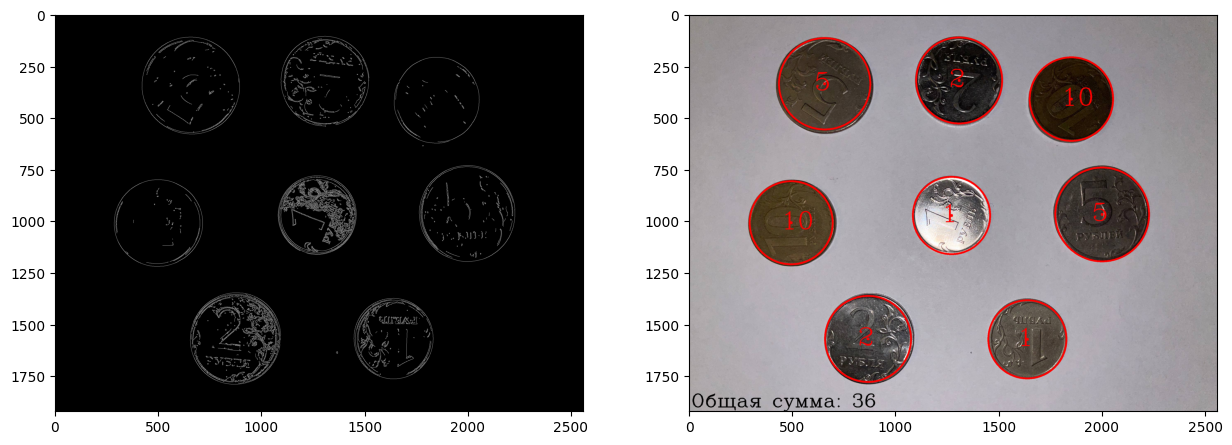

In [611]:
coin_classification1('test1.jpg', (3,3), 1.2, 150,
                     50, 100, 150, 270)

### Тест на 20 монетах

In [529]:
def coin_classification2(image_path, GaussMatrix, dp, minDist,
                         param1, param2, minRadius, maxRadius):
  #1 Сбор изображения
  image = cv.imread(image_path)


  #2 Предварительная обработка изображения
      # Преобразуйте изображение в оттенки серого
  gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
      # Примените размытие Гаусса для уменьшения шума
  gray = cv.GaussianBlur(gray, GaussMatrix, 0)
      # Используйте оператор Кэнни для обнаружения краев
  edges = cv.Canny(gray, 100, 200, apertureSize=3)


  #3 Обнаружение кругов
      # Используйте преобразование Хафа для обнаружения кругов на изображении
  dp = dp          # Параметр разрешения аккумуляторного массива
  minDist = minDist     # Минимальное расстояние между центрами
  param1 = param1       # Порог для метода Кэнни
  param2 = param2      # Порог для функции HoughCircles (чем меньше, тем больше ложных кругов)
  minRadius = minRadius    # Минимальный радиус круга
  maxRadius = maxRadius   # Максимальный радиус круга

  circles = cv.HoughCircles(gray, cv.HOUGH_GRADIENT, dp, minDist,
                            param1=param1, param2=param2,
                            minRadius=minRadius, maxRadius=maxRadius)
      # Получите координаты центров и радиусов обнаруженных кругов
  img_circles = image.copy()

  if circles is not None:
    circles = np.uint16(np.around(circles))
    max_radius = max([c[2] for c in circles[0, :]])
    coin_summ = 0

    for circle in circles[0, :]:
      center = (circle[0], circle[1])
      radius = circle[2]

      cv.circle(img_circles, center, radius, (0, 0, 255), 8)
      cv.circle(img_circles, center, 2, (0, 0, 255), 9)

      if radius < (max_radius * 0.84):
        coin_value = '1'
      elif radius < int(max_radius * 0.9):
        coin_value = '10'
      elif radius < int(max_radius * 0.925):
        coin_value = '2'
      else:
        coin_value = '5'

      fontFace = cv.FONT_HERSHEY_COMPLEX
      fontScale = 4
      cv.putText(img_circles, coin_value, (circle[0]-50, circle[1]+30), fontFace, fontScale, (0, 0, 255), 3)

      coin_summ += int(coin_value)

    cv.putText(img_circles, f'Общая сумма: {coin_summ}', (10, img_circles.shape[0]-20), cv.FONT_HERSHEY_COMPLEX, 3, (0,0,0), 3)
    print(sorted([int(c[2]) for c in circles[0, :]]))
    print(max_radius)
  else:
    print('Круги не найдены')

  plt.figure(figsize=(15,10))

  plt.subplot(1,2,1)
  plt.imshow(edges, cmap='gray')

  plt.subplot(1,2,2)
  plt.imshow(cv.cvtColor(img_circles, cv.COLOR_BGR2RGB))

  plt.show()

[142, 145, 145, 146, 148, 149, 156, 157, 157, 158, 160, 162, 163, 164, 165, 167, 173, 174, 176, 181]
181


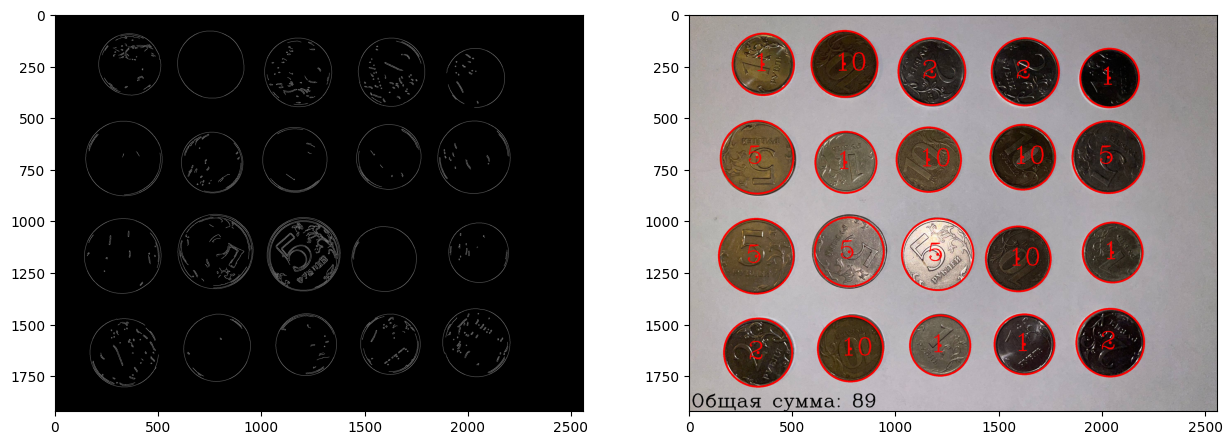

In [530]:
coin_classification2('test2.jpg', (9,9), 1.2, 150,
                     150, 80, 90, 260)

### Тест на 30 монетах

In [607]:
def coin_classification3(image_path, GaussMatrix, dp, minDist,
                         param1, param2, minRadius, maxRadius):
  #1 Сбор изображения
  image = cv.imread(image_path)


  #2 Предварительная обработка изображения
      # Преобразуйте изображение в оттенки серого
  gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
      # Примените размытие Гаусса для уменьшения шума
  gray = cv.GaussianBlur(gray, GaussMatrix, 0)
      # Используйте оператор Кэнни для обнаружения краев
  edges = cv.Canny(gray, 100, 200, apertureSize=3)


  #3 Обнаружение кругов
      # Используйте преобразование Хафа для обнаружения кругов на изображении
  dp = dp          # Параметр разрешения аккумуляторного массива
  minDist = minDist     # Минимальное расстояние между центрами
  param1 = param1       # Порог для метода Кэнни
  param2 = param2      # Порог для функции HoughCircles (чем меньше, тем больше ложных кругов)
  minRadius = minRadius    # Минимальный радиус круга
  maxRadius = maxRadius   # Максимальный радиус круга

  circles = cv.HoughCircles(gray, cv.HOUGH_GRADIENT, dp, minDist,
                            param1=param1, param2=param2,
                            minRadius=minRadius, maxRadius=maxRadius)
      # Получите координаты центров и радиусов обнаруженных кругов
  img_circles = image.copy()

  if circles is not None:
    circles = np.uint16(np.around(circles))
    max_radius = max([c[2] for c in circles[0, :]])
    coin_summ = 0
    coins = []

    for circle in circles[0, :]:
      center = (circle[0], circle[1])
      radius = circle[2]

      cv.circle(img_circles, center, radius, (0, 0, 255), 8)
      cv.circle(img_circles, center, 2, (0, 0, 255), 9)

      if radius < int(max_radius * 0.85):
        coin_value = '1'
      elif radius < int(max_radius * 0.88):
        coin_value = '10'
      elif radius < int(max_radius * 0.925):
        coin_value = '2'
      else:
        coin_value = '5'

      fontFace = cv.FONT_HERSHEY_COMPLEX
      fontScale = 4
      cv.putText(img_circles, coin_value, (circle[0]-55, circle[1]+30), fontFace, fontScale, (0, 0, 255), 3)

      coin_summ += int(coin_value)
      coins.append(int(coin_value))

    cv.putText(img_circles, f'Общая сумма: {coin_summ}', (10, img_circles.shape[0]-20), cv.FONT_HERSHEY_COMPLEX, 3, (0,0,0), 3)
    print(sorted([int(c[2]) for c in circles[0, :]]))
    print(max_radius)
    print(sorted(coins))
  else:
    print('Круги не найдены')

  plt.figure(figsize=(15,10))

  plt.subplot(1,2,1)
  plt.imshow(edges, cmap='gray')

  plt.subplot(1,2,2)
  plt.imshow(cv.cvtColor(img_circles, cv.COLOR_BGR2RGB))

  plt.show()

[113, 115, 115, 115, 115, 116, 117, 117, 117, 122, 123, 124, 124, 124, 125, 125, 126, 126, 127, 128, 129, 129, 131, 133, 139, 139, 139, 140, 143, 145]
145
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 5, 5, 5, 5, 5, 5, 10, 10, 10, 10, 10, 10, 10, 10]


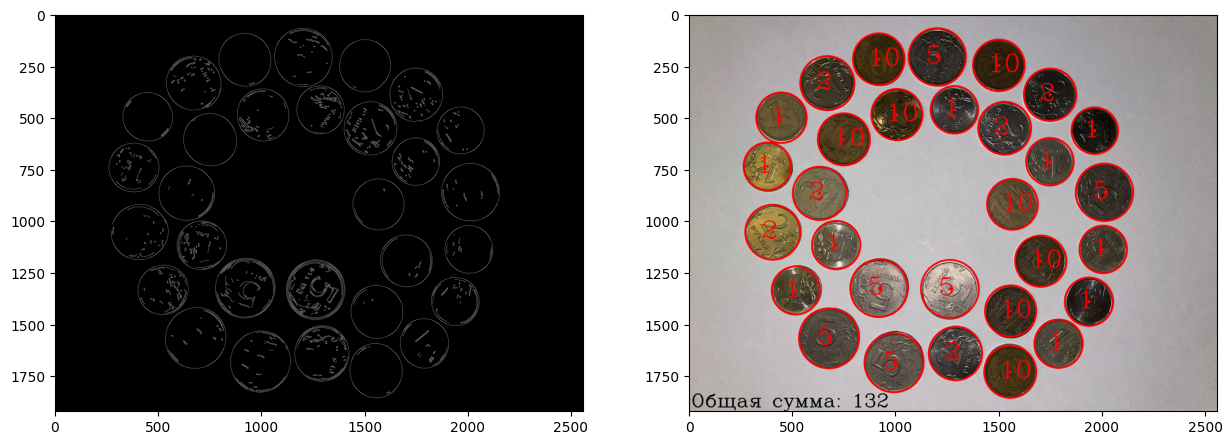

In [608]:
coin_classification3('test3.jpg', (9,9), 1.1, 130,
                     90, 45, 110, 160)

### **Требования к реализации:**



- Использовать только библиотеку **OpenCV** и стандартные библиотеки Python (например, **NumPy**).
- Код должен быть хорошо документирован с комментариями для каждого основного блока.
- Предусмотреть возможность настройки параметров обработки через трекбары или отдельные переменные.



### **Рекомендации:**




- **Преобразование Хафа** для кругов является удобным инструментом для обнаружения круглых объектов на изображении.
- **Пороговые значения радиусов** необходимо подобрать экспериментально, протестировав на образцах монет разных номиналов.
- **Обработка перекрывающихся монет** может потребовать более сложных алгоритмов, таких как водоразделение или использование градиентных признаков.
- Тестируйте программу на различных изображениях с разным количеством и расположением монет, а также при разном освещении.





### **Ожидаемый результат:**




В результате выполнения задания вы получите программу, которая способна:

- Принимать на вход изображение с монетами.
- Обрабатывать изображение и обнаруживать монеты без использования библиотеки cvzone.
- Определять номинал каждой монеты на основе ее радиуса или других признаков.
- Вычислять и отображать общую сумму монет на изображении.



---

**Пример использования программы:**

- Пользователь запускает программу.
- Загружается изображение с монетами.
- Программа обрабатывает изображение, отмечает каждую монету и подписывает ее номинал.
- Отображается изображение с результатами и выводится общая сумма, например: **"Общая сумма: 37 рублей"**.



---

**Заметка:**

Данный проект позволит вам:

- Изучить и применить технологии обработки изображений с помощью OpenCV без привлечения сторонних библиотек.
- Научиться решать практические задачи компьютерного зрения, применяя базовые методы и улучшая их по мере необходимости.




---

**Советы по реализации:**

- **Настройка параметров:**
  - Для преобразования Хафа используйте функцию `cv2.HoughCircles()`.
  - Экспериментируйте с параметрами `dp`, `minDist`, `param1`, `param2`, `minRadius`, `maxRadius`.
- **Отображение результатов:**
  - Используйте функцию `cv2.circle()` для рисования окружностей.
  - Для отображения текста воспользуйтесь `cv2.putText()`.
- **Обработка ошибок:**
  - Обрабатывайте случаи, когда преобразование Хафа не обнаруживает ни одной монеты.
  - Предусмотрите проверку входных данных и вывод информативных сообщений для пользователя.